# Rational Family Audit
## tl;dr
Este notebook muestra las comparaciones exactas ejecutadas con Gambit racional y el baseline poliédrico. La comparación es entre productos de envolventes convexas compatibles; no se convexifica la unión completa de equilibrios.

## Context & Methods
Gambit16.4.1 lee el NFG real y enumera extremos racionales. El código nuevo proyecta marginales por tipo, construye el grafo de compatibilidad usando payoffs directos y enumera bicliques máximos.
### Key Assumptions
Dos prestamistas y dos tipos; señales condicionalmente independientes; prior interior; payoff a_i(theta+alpha*a_j-c). La reconstrucción depende de la enumeración externa completa. Sin inferencia causal ni datos observados; S2 parcial.

In [1]:
import csv,json
from pathlib import Path
print(json.loads(Path('results/config.json').read_text()))
print(json.loads(Path('results/metadata.json').read_text()))

{'regular': {'prior': 0.5, 'accuracy': 0.8, 'cost': 0.9, 'complementarity': 0.8}, 'coordination_family': {'prior': 0.5, 'accuracy': 0.5, 'cost': 0.9, 'complementarity': 0.8}, 'full_indifference': {'prior': 0.5, 'accuracy': 0.5, 'cost': 0.5, 'complementarity': 0}, 'singular_isolated': {'prior': 0.5, 'accuracy': 1, 'cost': 1, 'complementarity': 0.8}, 'near_family': {'prior': 0.5, 'accuracy': 0.500000001, 'cost': 0.9, 'complementarity': 0.8}, 'random_0': {'prior': 0.4, 'accuracy': 0.5, 'cost': 0.8, 'complementarity': 0.8}, 'random_1': {'prior': 0.3, 'accuracy': 1.0, 'cost': 0.2, 'complementarity': 0.8}, 'random_2': {'prior': 0.5, 'accuracy': 0.9, 'cost': 0.9, 'complementarity': 0.8}, 'random_3': {'prior': 0.6, 'accuracy': 0.9, 'cost': 0.9, 'complementarity': 0.8}, 'random_4': {'prior': 0.8, 'accuracy': 0.7, 'cost': 1.0, 'complementarity': 0.8}, 'random_5': {'prior': 0.3, 'accuracy': 0.8, 'cost': 0.9, 'complementarity': 0.8}, 'random_6': {'prior': 0.5, 'accuracy': 0.9, 'cost': 1.0, 'comple

## Data
Matrices sintéticas racionales .nfg; el parser externo verifica las32 entradas. Perfiles crudos y familias exactas están en profiles.csv y families.json. Seed20261017.

In [2]:
print(Path('results/regular.nfg').read_text())
for row in list(csv.DictReader(Path('results/summary.csv').open()))[:5]:
    print({k:row[k] for k in ['scenario','gambit_profiles','baseline_families','reconstructed_families','dimensions','exact_equal','max_interim_regret']})

NFG 1 R "Bayesian credit freeze" { "Lender 0" "Lender 1" } { 4 4 }

0 0 -1/20 0 -7/20 0 -2/5 0 0 -1/20 111/500 111/500 -111/500 39/500 0 7/20 0 -7/20 39/500 -111/500 -39/500 -39/500 0 1/20 0 -2/5 7/20 0 1/20 0 2/5 2/5

{'scenario': 'regular', 'gambit_profiles': '5', 'baseline_families': '5', 'reconstructed_families': '5', 'dimensions': '[0, 0, 0, 0, 0]', 'exact_equal': 'True', 'max_interim_regret': '0'}
{'scenario': 'coordination_family', 'gambit_profiles': '11', 'baseline_families': '3', 'reconstructed_families': '3', 'dimensions': '[0, 2, 0]', 'exact_equal': 'True', 'max_interim_regret': '0'}
{'scenario': 'full_indifference', 'gambit_profiles': '16', 'baseline_families': '1', 'reconstructed_families': '1', 'dimensions': '[4]', 'exact_equal': 'True', 'max_interim_regret': '0'}
{'scenario': 'singular_isolated', 'gambit_profiles': '2', 'baseline_families': '2', 'reconstructed_families': '2', 'dimensions': '[0, 0]', 'exact_equal': 'True', 'max_interim_regret': '0'}
{'scenario': 'near_fam

## Results
Figura editable desde benchmarks/run.py, generada a partir de resultados ejecutados. Las barras derechas son controles negativos, no estimaciones empíricas.

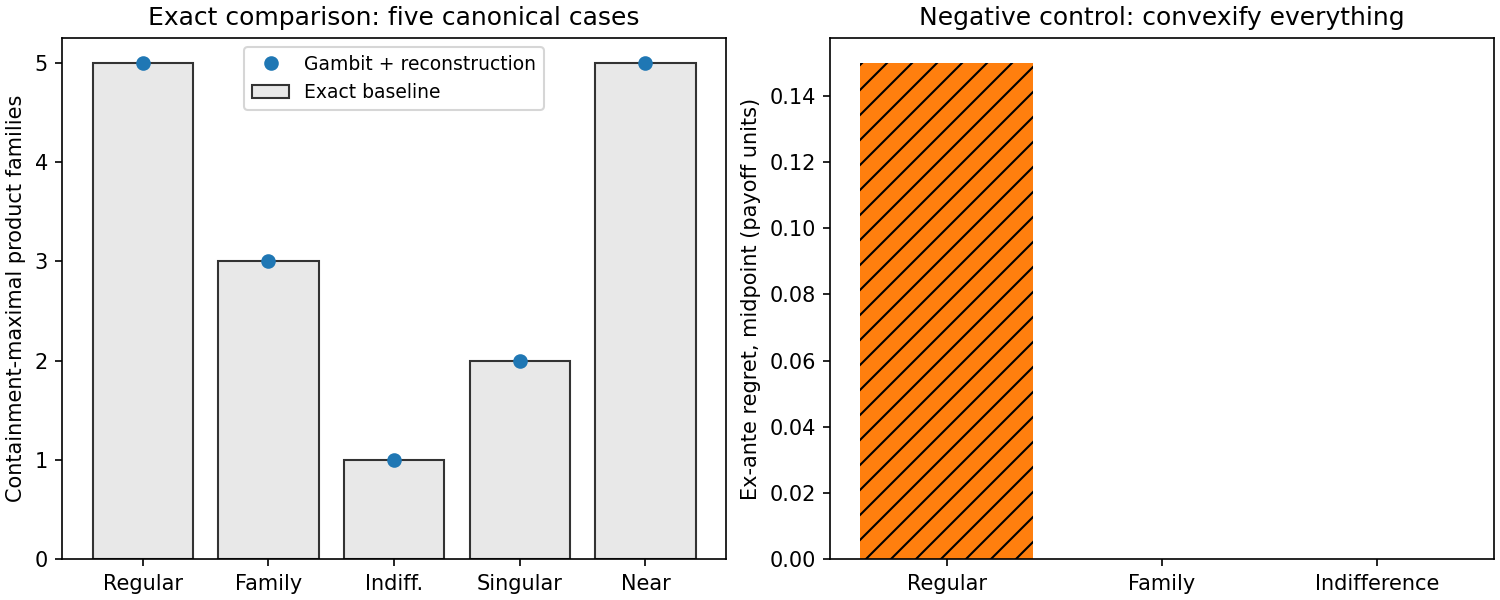

In [3]:
from IPython.display import Image,display
display(Image(filename='results/comparison.png'))

In [4]:
print(Path('results/ablations.csv').read_text())
print(Path('results/coverage.txt').read_text())

scenario,ablation,candidate,exact_exante_regret,true_max_dimension,first_profile_only_dimension,profiles
regular,convexify_all_equilibria,"[1/2,1/2,1/2,1/2]",3/20,0,0,5
coordination_family,convexify_all_equilibria,"[1/2,1/2,1/2,1/2]",0,2,0,11
full_indifference,convexify_all_equilibria,"[1/2,1/2,1/2,1/2]",0,4,0,16

Name              Stmts   Miss Branch BrPart  Cover   Missing
-------------------------------------------------------------
src/families.py      86      0     32      0   100%
-------------------------------------------------------------
TOTAL                86      0     32      0   100%



## Takeaways
La igualdad exacta de familias en los casos ejecutados amplía la evidencia S2, no demuestra un teorema de completitud general ni S3 del programa. Un punto o una envolvente global pierden la estructura de multiplicidad; ver informe.md para casos negativos, coste y límites.